##Load the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("../data/raw/supply_chain_master.csv")

df["Date"] = pd.to_datetime(df["Date"])

df = df.sort_values("Date")

df.head()

,Date,Product_ID,Warehouse,Product_Name,Category,Supplier_ID,Supplier_Name,Region,Unit_Cost,Unit_Price,...,COGS,Gross_Margin,Inventory_Level,Safety_Stock,Reorder_Point,Stockout_Flag,Order_Quantity,Lead_Time_Days,Delivery_Days,Promotion_Flag
0,2021-01-01,P001,WH01,Laptop,Electronics,S01,Supplier_01,North,61052.0,75587.15,...,1037884.0,247097.55,480,169,461,0,0,14,NaN,0
54784,2021-01-01,P007,WH05,Headphones,Home Appliances,S01,Supplier_01,Central,23386.0,27525.66,...,1941038.0,343591.78,524,54,1210,0,0,14,NaN,0
54783,2021-01-01,P007,WH04,Headphones,Home Appliances,S01,Supplier_01,East,23386.0,27525.66,...,1730564.0,306334.84,1525,169,1325,0,0,14,NaN,0
54782,2021-01-01,P007,WH03,Headphones,Home Appliances,S01,Supplier_01,South,23386.0,27525.66,...,1730564.0,306334.84,1076,169,1325,0,0,14,NaN,0
54781,2021-01-01,P007,WH02,Headphones,Home Appliances,S01,Supplier_01,West,23386.0,27525.66,...,2221670.0,393267.70,619,169,1325,0,0,14,NaN,0


##Moving Average

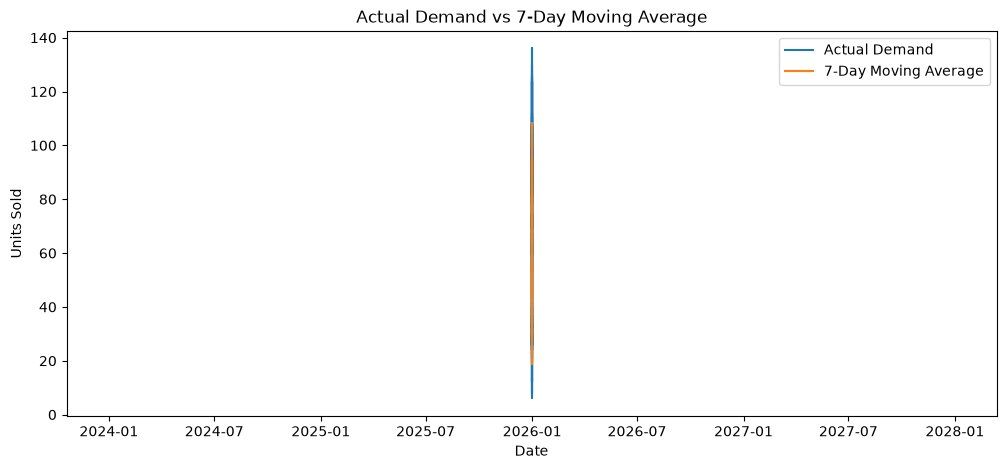

In [4]:
df["Moving_Average_7"] = (
    df["Units_Sold"]
    .rolling(window=7)
    .mean()
)

df[["Date", "Units_Sold", "Moving_Average_7"]].tail(20)

plt.figure(figsize=(12, 5))

plt.plot(
    df["Date"].tail(100),
    df["Units_Sold"].tail(100),
    label="Actual Demand"
)

plt.plot(
    df["Date"].tail(100),
    df["Moving_Average_7"].tail(100),
    label="7-Day Moving Average"
)

plt.title("Actual Demand vs 7-Day Moving Average")
plt.xlabel("Date")
plt.ylabel("Units Sold")
plt.legend()
plt.show()

df = df.sort_values(["Product_ID", "Date"])

df["Moving_Average_7"] = (
    df.groupby("Product_ID")["Units_Sold"]
      .transform(lambda x: x.rolling(7).mean())
)

Exponential Moving Average

In [5]:
df["EMA_7"] = (
    df.groupby("Product_ID")["Units_Sold"]
      .transform(lambda x: x.ewm(span=7, adjust=False).mean())
)
df[
    [
        "Date",
        "Product_ID",
        "Units_Sold",
        "Moving_Average_7",
        "EMA_7"
    ]
].tail(20)

,Date,Product_ID,Units_Sold,Moving_Average_7,EMA_7
456482,2025-12-28,P050,12,19.571429,17.847469
456481,2025-12-28,P050,19,18.714286,18.135602
456480,2025-12-28,P050,16,18.714286,17.601701
456484,2025-12-28,P050,16,17.428571,17.201276
456483,2025-12-28,P050,15,16.571429,16.650957
456486,2025-12-29,P050,17,15.857143,16.738218
456487,2025-12-29,P050,20,16.428571,17.553663
456485,2025-12-29,P050,8,15.857143,15.165248
456489,2025-12-29,P050,17,15.571429,15.623936
456488,2025-12-29,P050,15,15.428571,15.467952


Exponential Smoothing

d:\progect\supply-chain-decision-analytics\venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


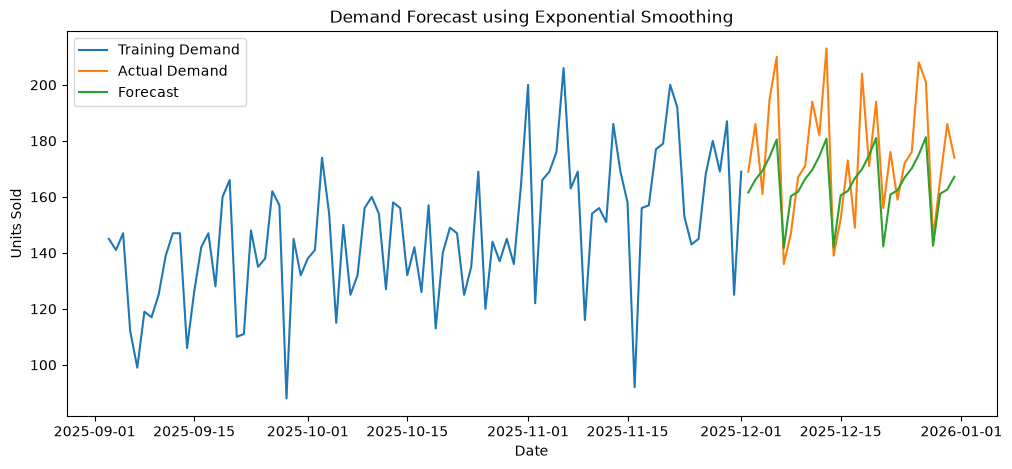

In [7]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

product_id = "P001"

product_df = df[
    df["Product_ID"] == product_id
].copy()

product_df = (
    product_df
    .groupby("Date")["Units_Sold"]
    .sum()
    .reset_index()
)

product_df = product_df.set_index("Date")

product_df.head()

train = product_df.iloc[:-30]
test = product_df.iloc[-30:]

from statsmodels.tsa.holtwinters import ExponentialSmoothing

model = ExponentialSmoothing(
    train["Units_Sold"],
    trend="add",
    seasonal="add",
    seasonal_periods=7
)

fit = model.fit()

forecast = fit.forecast(30)

forecast

plt.figure(figsize=(12, 5))

plt.plot(
    train.index[-90:],
    train["Units_Sold"].tail(90),
    label="Training Demand"
)

plt.plot(
    test.index,
    test["Units_Sold"],
    label="Actual Demand"
)

plt.plot(
    forecast.index,
    forecast,
    label="Forecast"
)

plt.title("Demand Forecast using Exponential Smoothing")
plt.xlabel("Date")
plt.ylabel("Units Sold")
plt.legend()
plt.show()



In [8]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

mae = mean_absolute_error(
    test["Units_Sold"],
    forecast
)

rmse = np.sqrt(
    mean_squared_error(
        test["Units_Sold"],
        forecast
    )
)

print("MAE:", mae)
print("RMSE:", rmse)

MAE: 13.441140009917385
RMSE: 16.54413882497634


In [12]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Create 7-day moving average on the complete product history
product_df["Moving_Average_7"] = (
    product_df["Units_Sold"]
    .rolling(window=7)
    .mean()
)

# Get moving-average values for the test period
ma_forecast = product_df.loc[
    test.index, "Moving_Average_7"
]

# Create comparison table
comparison = pd.DataFrame({
    "Actual": test["Units_Sold"],
    "Moving_Average": ma_forecast,
    "Exponential_Smoothing": forecast
}).dropna()

print("Comparison rows:", len(comparison))
comparison.head()

ma_mae = mean_absolute_error(
    comparison["Actual"],
    comparison["Moving_Average"]
)

ma_rmse = np.sqrt(
    mean_squared_error(
        comparison["Actual"],
        comparison["Moving_Average"]
    )
)

es_mae = mean_absolute_error(
    comparison["Actual"],
    comparison["Exponential_Smoothing"]
)

es_rmse = np.sqrt(
    mean_squared_error(
        comparison["Actual"],
        comparison["Exponential_Smoothing"]
    )
)

print("Moving Average MAE:", round(ma_mae, 2))
print("Moving Average RMSE:", round(ma_rmse, 2))

print("Exponential Smoothing MAE:", round(es_mae, 2))
print("Exponential Smoothing RMSE:", round(es_rmse, 2))

Comparison rows: 30
Moving Average MAE: 16.93
Moving Average RMSE: 21.11
Exponential Smoothing MAE: 13.44
Exponential Smoothing RMSE: 16.54


In [13]:
from sklearn.metrics import mean_absolute_percentage_error

ma_mape = mean_absolute_percentage_error(
    comparison["Actual"],
    comparison["Moving_Average"]
) * 100

es_mape = mean_absolute_percentage_error(
    comparison["Actual"],
    comparison["Exponential_Smoothing"]
) * 100

print("Moving Average MAPE:", round(ma_mape, 2), "%")
print("Exponential Smoothing MAPE:", round(es_mape, 2), "%")

Moving Average MAPE: 9.85 %
Exponential Smoothing MAPE: 7.33 %


SARIMA Forecasting

In [14]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

product_id = "P001"

product_df = df[
    df["Product_ID"] == product_id
].copy()

product_df = (
    product_df
    .groupby("Date")["Units_Sold"]
    .sum()
    .sort_index()
)

product_df.head()

Date
2021-01-01     94
2021-01-02    124
2021-01-03     80
2021-01-04     94
2021-01-05    107
Name: Units_Sold, dtype: int64

In [15]:
train = product_df.iloc[:-30]
test = product_df.iloc[-30:]

print("Training observations:", len(train))
print("Testing observations:", len(test))

Training observations: 1796
Testing observations: 30


In [16]:
sarima_model = SARIMAX(
    train,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 7),
    enforce_stationarity=False,
    enforce_invertibility=False
)

sarima_fit = sarima_model.fit(disp=False)

sarima_forecast = sarima_fit.forecast(steps=30)

sarima_forecast

d:\progect\supply-chain-decision-analytics\venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
d:\progect\supply-chain-decision-analytics\venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


2025-12-02    161.604763
2025-12-03    166.235407
2025-12-04    169.786758
2025-12-05    174.257917
2025-12-06    180.755408
2025-12-07    141.254624
2025-12-08    160.637963
2025-12-09    161.841246
2025-12-10    166.416177
2025-12-11    169.722834
2025-12-12    174.706402
2025-12-13    180.824617
2025-12-14    142.065970
2025-12-15    160.637337
2025-12-16    162.124239
2025-12-17    166.697333
2025-12-18    169.995919
2025-12-19    174.996388
2025-12-20    181.102093
2025-12-21    142.367925
2025-12-22    160.912509
2025-12-23    162.408766
2025-12-24    166.981800
2025-12-25    170.280119
2025-12-26    175.281146
2025-12-27    181.386438
2025-12-28    142.653077
2025-12-29    161.196778
2025-12-30    162.693344
2025-12-31    167.266376
Freq: D, Name: predicted_mean, dtype: float64

SARIMA MAE: 13.4
SARIMA RMSE: 16.49
SARIMA MAPE: 7.31 %


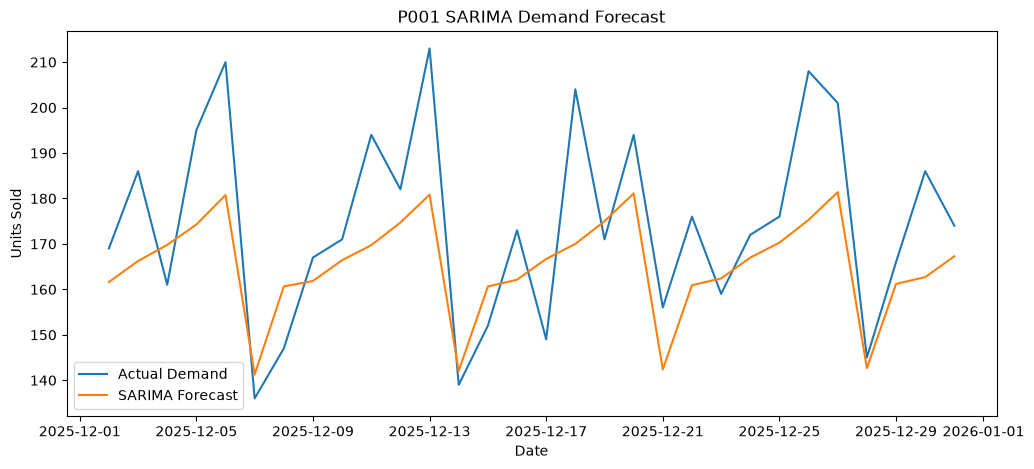

In [18]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error
)

sarima_mae = mean_absolute_error(
    test,
    sarima_forecast
)

sarima_rmse = np.sqrt(
    mean_squared_error(
        test,
        sarima_forecast
    )
)

sarima_mape = mean_absolute_percentage_error(
    test,
    sarima_forecast
) * 100

print("SARIMA MAE:", round(sarima_mae, 2))
print("SARIMA RMSE:", round(sarima_rmse, 2))
print("SARIMA MAPE:", round(sarima_mape, 2), "%")

plt.figure(figsize=(12, 5))

plt.plot(
    test.index,
    test,
    label="Actual Demand"
)

plt.plot(
    sarima_forecast.index,
    sarima_forecast,
    label="SARIMA Forecast"
)

plt.title("P001 SARIMA Demand Forecast")
plt.xlabel("Date")
plt.ylabel("Units Sold")
plt.legend()

plt.show()

## Model Comparison Across All Products

In [20]:
import pandas as pd
import numpy as np

from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error
)

results = []

products = df["Product_ID"].unique()

for product_id in products:

    print(f"Processing {product_id}...")

    # -----------------------------
    # Prepare product demand
    # -----------------------------
    product_df = df[
        df["Product_ID"] == product_id
    ].copy()

    product_df = (
        product_df
        .groupby("Date")["Units_Sold"]
        .sum()
        .sort_index()
    )

    # Need enough history
    if len(product_df) < 60:
        continue

    # -----------------------------
    # Train / Test split
    # -----------------------------
    train = product_df.iloc[:-30]
    test = product_df.iloc[-30:]

    # ==================================================
    # 1. Moving Average
    # ==================================================

    ma_series = product_df.rolling(window=7).mean()

    ma_forecast = ma_series.loc[test.index]

    comparison = pd.DataFrame({
        "Actual": test,
        "Forecast": ma_forecast
    }).dropna()

    if len(comparison) > 0:

        ma_mae = mean_absolute_error(
            comparison["Actual"],
            comparison["Forecast"]
        )

        ma_rmse = np.sqrt(
            mean_squared_error(
                comparison["Actual"],
                comparison["Forecast"]
            )
        )

        ma_mape = mean_absolute_percentage_error(
            comparison["Actual"],
            comparison["Forecast"]
        ) * 100

    else:
        ma_mae = np.nan
        ma_rmse = np.nan
        ma_mape = np.nan

    # ==================================================
    # 2. Exponential Smoothing
    # ==================================================

    try:

        es_model = ExponentialSmoothing(
            train,
            trend="add",
            seasonal="add",
            seasonal_periods=7
        )

        es_fit = es_model.fit()

        es_forecast = es_fit.forecast(30)

        es_mae = mean_absolute_error(
            test,
            es_forecast
        )

        es_rmse = np.sqrt(
            mean_squared_error(
                test,
                es_forecast
            )
        )

        es_mape = mean_absolute_percentage_error(
            test,
            es_forecast
        ) * 100

    except Exception:

        es_mae = np.nan
        es_rmse = np.nan
        es_mape = np.nan

    # ==================================================
    # 3. SARIMA
    # ==================================================

    try:

        sarima_model = SARIMAX(
            train,
            order=(1, 1, 1),
            seasonal_order=(1, 1, 1, 7),
            enforce_stationarity=False,
            enforce_invertibility=False
        )

        sarima_fit = sarima_model.fit(
            disp=False
        )

        sarima_forecast = sarima_fit.forecast(
            steps=30
        )

        sarima_mae = mean_absolute_error(
            test,
            sarima_forecast
        )

        sarima_rmse = np.sqrt(
            mean_squared_error(
                test,
                sarima_forecast
            )
        )

        sarima_mape = mean_absolute_percentage_error(
            test,
            sarima_forecast
        ) * 100

    except Exception:

        sarima_mae = np.nan
        sarima_rmse = np.nan
        sarima_mape = np.nan

    # ==================================================
    # Store results
    # ==================================================

    results.append({
        "Product_ID": product_id,

        "MA_MAE": ma_mae,
        "MA_RMSE": ma_rmse,
        "MA_MAPE": ma_mape,

        "ES_MAE": es_mae,
        "ES_RMSE": es_rmse,
        "ES_MAPE": es_mape,

        "SARIMA_MAE": sarima_mae,
        "SARIMA_RMSE": sarima_rmse,
        "SARIMA_MAPE": sarima_mape
    })

    results_df = pd.DataFrame(results)

results_df.head()

print("Products evaluated:", len(results_df))

average_results = results_df[
    [
        "MA_MAE",
        "MA_RMSE",
        "MA_MAPE",

        "ES_MAE",
        "ES_RMSE",
        "ES_MAPE",

        "SARIMA_MAE",
        "SARIMA_RMSE",
        "SARIMA_MAPE"
    ]
].mean()

average_results

results_df["Best_Model"] = results_df[
    [
        "MA_MAPE",
        "ES_MAPE",
        "SARIMA_MAPE"
    ]
].idxmin(axis=1)

results_df["Best_Model"] = (
    results_df["Best_Model"]
    .map({
        "MA_MAPE": "Moving Average",
        "ES_MAPE": "Exponential Smoothing",
        "SARIMA_MAPE": "SARIMA"
    })
)

results_df[
    [
        "Product_ID",
        "MA_MAPE",
        "ES_MAPE",
        "SARIMA_MAPE",
        "Best_Model"
    ]
].head(20)

model_counts = results_df["Best_Model"].value_counts()

model_counts

results_df.to_csv(
    "../data/processed/forecast_model_comparison.csv",
    index=False
)

Processing P001...


d:\progect\supply-chain-decision-analytics\venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
d:\progect\supply-chain-decision-analytics\venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
d:\progect\supply-chain-decision-analytics\venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


Processing P002...


d:\progect\supply-chain-decision-analytics\venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
d:\progect\supply-chain-decision-analytics\venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
d:\progect\supply-chain-decision-analytics\venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


Processing P003...


...

Processing P049...


d:\progect\supply-chain-decision-analytics\venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
d:\progect\supply-chain-decision-analytics\venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
d:\progect\supply-chain-decision-analytics\venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


Processing P050...


d:\progect\supply-chain-decision-analytics\venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
d:\progect\supply-chain-decision-analytics\venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
d:\progect\supply-chain-decision-analytics\venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


Products evaluated: 50


In [22]:
average_results = results_df[
    [
        "MA_MAE",
        "MA_RMSE",
        "MA_MAPE",
        "ES_MAE",
        "ES_RMSE",
        "ES_MAPE",
        "SARIMA_MAE",
        "SARIMA_RMSE",
        "SARIMA_MAPE"
    ]
].mean()

print(average_results)

results_df["Best_Model"] = results_df[
    [
        "MA_MAPE",
        "ES_MAPE",
        "SARIMA_MAPE"
    ]
].idxmin(axis=1)

results_df["Best_Model"] = (
    results_df["Best_Model"]
    .map({
        "MA_MAPE": "Moving Average",
        "ES_MAPE": "Exponential Smoothing",
        "SARIMA_MAPE": "SARIMA"
    })
)

print(results_df["Best_Model"].value_counts())

results_df.to_csv(
    "../data/processed/forecast_model_comparison.csv",
    index=False
)

print("Forecast comparison saved successfully.")

MA_MAE         30.964857
MA_RMSE        38.852407
MA_MAPE         9.519996
ES_MAE         26.538739
ES_RMSE        32.931804
ES_MAPE         7.910113
SARIMA_MAE     25.630041
SARIMA_RMSE    31.956584
SARIMA_MAPE     7.713793
dtype: float64
Best_Model
SARIMA                   40
Moving Average            7
Exponential Smoothing     3
Name: count, dtype: int64
Forecast comparison saved successfully.


In [27]:
import sys
sys.path.append("../src")

from safety_stock import calculate_safety_stock
from reorder import calculate_reorder_point

ImportError: cannot import name 'calculate_reorder_point' from 'reorder' (d:\progect\supply-chain-decision-analytics\notebooks\../src\reorder.py)

## Forecasting Model Selection

Three forecasting approaches were evaluated across all 50 products using a 30-day holdout period:

- Moving Average
- Exponential Smoothing
- SARIMA

SARIMA achieved the lowest average forecasting error, with an average MAE of 25.63 units, RMSE of 31.96 units, and MAPE of 7.71%.

SARIMA was also the best-performing model for 40 out of 50 products.

Therefore, SARIMA was selected as the primary forecasting approach for the inventory planning stage. The forecasts will be used to estimate future demand and support safety-stock and reorder-point calculations.

Model selection was based on out-of-sample forecasting performance rather than model complexity.